Q. no 1 
Equillibriun conversion checker
In a dilute liquid phase reactor the raction A+B gives C reaches equillibrium. Initial concentrations are initial [A] = 0.5, [b] initial = 0.5 and [C] initial = 0 mol/L. If x mol/L of C is formed, Kc = x/(0.5-x)2, which arranges to the quadraticequation Kc.x2-(Kc+1).x+0.25.Kc = 0
write a python program that:
(a) reads kc using input (), prints the data type of the raw input and of the converted value, and shows a clear message (no crash) if the text is not a number or if Kc-< 0;
(b) finds a,b,c, the descriminant and both roots;
(c) selects the physically meaningful root (0<- x <- 0.5);
(d) prints equillibrium [A],[B], [C] (3 decimals) and conversion of the limiting reactanat = x/[A] initial* 100 (%):
(e) classifies the conversion using if/elif/else: -> 70% "High", -> 40 % "Moderate", otherwise "Low".
Test with Kc 6, Kc = 0.5,
Kc + abc and Kc = -2

In [1]:
import math

raw_kc = input("Enter Kc: ")

print("Raw input:", raw_kc)
print("Raw input type:", type(raw_kc))

try:
    kc = float(raw_kc)
except ValueError:
    print("Error: Kc must be a number.")
else:
    print("Converted Kc:", kc)
    print("Converted value type:", type(kc))

    if not math.isfinite(kc):
        print("Error: Kc must be a finite number.")
    elif kc < 0:
        print("Error: Kc cannot be negative.")
    else:
        # Kc*x^2 - (Kc+1)*x + 0.25*Kc = 0
        a = kc
        b = -(kc + 1)
        c = 0.25 * kc

        print(f"\na = {a}")
        print(f"b = {b}")
        print(f"c = {c}")

        if a == 0:
            # At Kc = 0, the equation becomes -x = 0, not a quadratic.
            discriminant = b**2 - 4 * a * c
            root1 = 0.0
            root2 = None

            print(f"Discriminant = {discriminant}")
            print(f"Root 1 = {root1}")
            print("Root 2 = not defined (the equation is linear)")

            print("No root satisfies the strict physical condition 0 < x < 0.5.")
        else:
            discriminant = b**2 - 4 * a * c
            print(f"Discriminant = {discriminant}")

            if discriminant < 0:
                print("Error: There are no real roots.")
            else:
                sqrt_discriminant = math.sqrt(discriminant)
                root1 = (-b + sqrt_discriminant) / (2 * a)
                root2 = (-b - sqrt_discriminant) / (2 * a)

                print(f"Root 1 = {root1}")
                print(f"Root 2 = {root2}")

                physical_roots = [
                    root for root in (root1, root2)
                    if 0 < root < 0.5
                ]

                if not physical_roots:
                    print("Error: No root satisfies the physical condition 0 < x < 0.5.")
                else:
                    x = physical_roots[0]

                    initial_a = 0.5
                    initial_b = 0.5
                    equilibrium_a = initial_a - x
                    equilibrium_b = initial_b - x
                    equilibrium_c = x

                    conversion = (x / initial_a) * 100

                    print(f"\nPhysical root x = {x:.6f} mol/L")
                    print(f"Equilibrium [A] = {equilibrium_a:.3f} mol/L")
                    print(f"Equilibrium [B] = {equilibrium_b:.3f} mol/L")
                    print(f"Equilibrium [C] = {equilibrium_c:.3f} mol/L")
                    print(f"Limiting reactant conversion = {conversion:.2f}%")

                    if conversion >= 70:
                        classification = "High"
                    elif conversion >= 40:
                        classification = "Moderate"
                    else:
                        classification = "Low"

                    print(f"Conversion classification: {classification}")

Raw input: 4
Raw input type: <class 'str'>
Converted Kc: 4.0
Converted value type: <class 'float'>

a = 4.0
b = -5.0
c = 1.0
Discriminant = 9.0
Root 1 = 1.0
Root 2 = 0.25

Physical root x = 0.250000 mol/L
Equilibrium [A] = 0.250 mol/L
Equilibrium [B] = 0.250 mol/L
Equilibrium [C] = 0.250 mol/L
Limiting reactant conversion = 50.00%
Conversion classification: Moderate


Batch reactor simulation and batch tracking
Part A. A pollutant in wastewater is degraded in batch photoractor by a first order reaction, dC/dt = -kC. Use the euler method: C_new = C_old _k.C_old.delta t. Take C initial = 1.0 mil/L, k=0.12 min^-1, delta + 0.5 min.
(a) using a loop, simulate 5 minutes and print a table of time (min), Concentration (mol/L) and conversion (%).
(b) using math.exp(), calculate the exact value Cinitiale^(-kt) at 5 min and print the absolute error of the euler result.
(c) using a while loop,repeat the simulation until conversion reaches 70% or time reaches 100 min. Print the time needed and the final concentration

Part b. Storage - tank lots such as TK0045-LOT19 are stored as text. Write a program that reads a lot code, loop through each character, and prints the number of digits and the sum of the digits. Show a message for an empty code and for a code with no digits, Teat with TK0045_LOT19, an empty code and ABCDEF.

Part A: Batch reactor

In [4]:


import math

initial_concentration = 1.0  # mol/L
k = 0.12                     # min^-1
delta_t = 0.5                # min

# (a) Euler simulation for 5 minutes
time = 0.0
concentration = initial_concentration

print("Time (min)\tConcentration (mol/L)\tConversion (%)")
print(f"{time:.1f}\t\t{concentration:.4f}\t\t\t0.00")

while time < 5.0:
    concentration = concentration - k * concentration * delta_t
    time += delta_t

    conversion = (
        (initial_concentration - concentration) / initial_concentration
    ) * 100

    print(f"{time:.1f}\t\t{concentration:.4f}\t\t\t{conversion:.2f}")

euler_concentration = concentration

# (b) Exact concentration and absolute error at 5 minutes
exact_concentration = initial_concentration * math.exp(-k * 5.0)
absolute_error = abs(euler_concentration - exact_concentration)

print(f"\nExact concentration at 5 min: {exact_concentration:.6f} mol/L")
print(f"Absolute error: {absolute_error:.6f} mol/L")

# (c) Continue with a while loop until conversion reaches 70%
# or the elapsed time reaches 100 minutes.
time = 0.0
concentration = initial_concentration
conversion = 0.0

while conversion < 70.0 and time < 100.0:
    concentration = concentration - k * concentration * delta_t
    time += delta_t
    conversion = (
        (initial_concentration - concentration) / initial_concentration
    ) * 100

print(f"\nTime to reach 70% conversion or the 100 min limit: {time:.1f} min")
print(f"Final concentration: {concentration:.4f} mol/L")
print(f"Final conversion: {conversion:.2f}%")




Time (min)	Concentration (mol/L)	Conversion (%)
0.0		1.0000			0.00
0.5		0.9400			6.00
1.0		0.8836			11.64
1.5		0.8306			16.94
2.0		0.7807			21.93
2.5		0.7339			26.61
3.0		0.6899			31.01
3.5		0.6485			35.15
4.0		0.6096			39.04
4.5		0.5730			42.70
5.0		0.5386			46.14

Exact concentration at 5 min: 0.548812 mol/L
Absolute error: 0.010197 mol/L

Time to reach 70% conversion or the 100 min limit: 10.0 min
Final concentration: 0.2901 mol/L
Final conversion: 70.99%


Part B: Batch lot tracking

In [5]:
lot_code = input("Enter the lot code: ").strip()

digit_count = 0
digit_sum = 0

for character in lot_code:
    if character.isdecimal():
        digit_count += 1
        digit_sum += int(character)

if lot_code == "":
    print("The lot code is empty.")
elif digit_count == 0:
    print("The lot code contains no digits.")

print(f"Number of digits: {digit_count}")
print(f"Sum of digits: {digit_sum}")

Number of digits: 1
Sum of digits: 6


Feed - blend screening and sampling schedule

Part A. A plant has n candidate feed components and wants to blrnd r of them (order dors not matter). Write a recursive funtion factorial(n) (remember the base case for 0!) and a function combination(n,r) = n!/(r!/(n-1)!) that uses it. Reject invalid input (negative values, r>n). Print the number of possible blendsd for n=8, r=4, and show the message for n=3, r=5.

Part B. During a cooling experiment, temprature readings are taken at times = Fibonacci number * 3 min. Write an iterative function fib_iter(n) that returns a list of thr first n fibonnaci numbers, and a recursive function fib_rec(k) that returns the k-th Fibonacci number (f initial = 0, F1 = 1). For n = 8, check that both functions agree and print a table: Reading No. | Fibonnaci tag| Time (min)

Part A: Blend combinations

In [6]:
def factorial(n):
    if not isinstance(n, int) or n < 0:
        raise ValueError("n must be a non-negative integer.")

    if n == 0:
        return 1

    return n * factorial(n - 1)


def combination(n, r):
    if not isinstance(n, int) or not isinstance(r, int):
        raise ValueError("n and r must be integers.")
    if n < 0 or r < 0:
        raise ValueError("n and r cannot be negative.")
    if r > n:
        raise ValueError("r cannot be greater than n.")

    return factorial(n) // (factorial(r) * factorial(n - r))


try:
    print("Possible blends for n=8, r=4:", combination(8, 4))
except ValueError as error:
    print("Invalid input:", error)

try:
    print("Possible blends for n=3, r=5:", combination(3, 5))
except ValueError as error:
    print("Invalid input:", error)

Possible blends for n=8, r=4: 70
Invalid input: r cannot be greater than n.


Part B: Fibonacci sampling schedule

In [7]:
def fib_iter(n):
    if not isinstance(n, int) or n < 0:
        raise ValueError("n must be a non-negative integer.")

    numbers = []
    first, second = 0, 1

    for _ in range(n):
        numbers.append(first)
        first, second = second, first + second

    return numbers


def fib_rec(k):
    if not isinstance(k, int) or k < 0:
        raise ValueError("k must be a non-negative integer.")

    if k == 0:
        return 0
    if k == 1:
        return 1

    return fib_rec(k - 1) + fib_rec(k - 2)


n = 8
fibonacci_numbers = fib_iter(n)
recursive_numbers = [fib_rec(k) for k in range(n)]

print("Iterative and recursive results agree:", fibonacci_numbers == recursive_numbers)
print("\nReading No.\tFibonacci tag\tTime (min)")

for reading_number, fib_number in enumerate(fibonacci_numbers, start=1):
    time_min = fib_number * 3
    print(f"{reading_number}\t\t{fib_number}\t\t{time_min}")

Iterative and recursive results agree: True

Reading No.	Fibonacci tag	Time (min)
1		0		0
2		1		3
3		1		3
4		2		6
5		3		9
6		5		15
7		8		24
8		13		39


Kinetics and gas data : pandas and metplotlib
Photocatalytic degradation of a dye was studied at two UV intensities. Concentration (mol/L) was recorded:
now this is a table with 3 rows:- Time_min, Run1_mol_L (low UV) and Run2_mol_L (high UV)
the values for Time_min are 0, 10, 20, 30, 40, 50
the values for Run1_mol_L (low UV) are 0.80, 0.54, 0.36,0.24, 0.16, 0.11
the values for Run2_mol_L (high UV) are 0.80, 0.44, 0.24, 0.13, 0.07, 0.04
(a) Create a Dataframe for this table. Save it as kinetics.csv(without the index column) and as kinetics.json. Read the CSV back and print its shape and data types.
(b) Print the mean and standard deviation of Run1 and Run2, and state which run shows more variation.
(c) Plot both runs on one graph (Time in x-axis) with title , axis labels with the units, legend and grid.
(d) Air is compressed slowly in a piston-cylinder vessel at constant temprature:
now comes another table with 6 rows namely Volume_L, 2, 3, 4, 5, 6 and the information in it is
for Volume_L is Pressure_bar
for 2 is 3.01
for 3 is 1.98
for 4 is 1.52
for 5 is 1.19
for 6 is 1.01

Plot pressure vs. volume as a scatter plot. Calculate k as mean of P*V and draw the reference curve P=k/V on the same graph. add title, labels with units and legend.

In [13]:
%pip install numpy pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 31.3 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 34.0 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 42.4 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 41.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 23.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 40.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [matplotlib]9 [matplotlib]

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


CSV shape: (6, 3)

CSV data types:
Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object

Run 1 mean: 0.368 mol/L
Run 1 standard deviation: 0.262 mol/L
Run 2 mean: 0.287 mol/L
Run 2 standard deviation: 0.290 mol/L
Run 2 shows more variation.


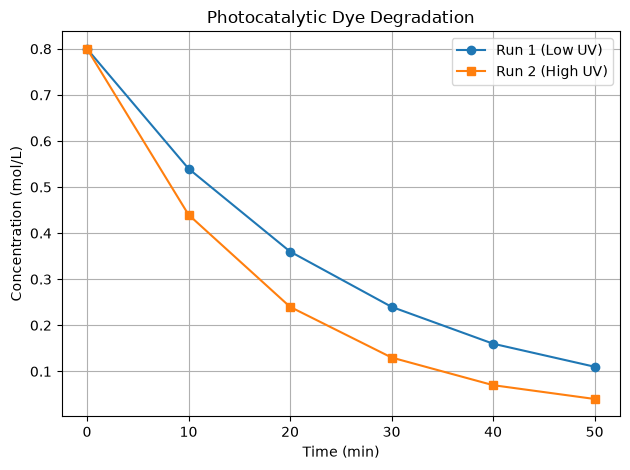


Mean value of P*V (k): 6.010 bar·L


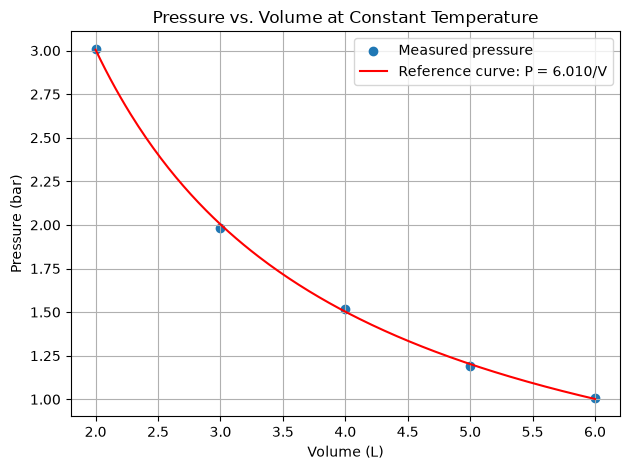

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Kinetics data
kinetics_df = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L": [0.80, 0.54, 0.36, 0.24, 0.16, 0.11],
    "Run2_mol_L": [0.80, 0.44, 0.24, 0.13, 0.07, 0.04],
})

# Save files without a CSV index column
kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=4)

# Read the CSV back and report its shape and data types
kinetics_readback = pd.read_csv("kinetics.csv")
print("CSV shape:", kinetics_readback.shape)
print("\nCSV data types:")
print(kinetics_readback.dtypes)

# Calculate means and standard deviations
run1_mean = kinetics_readback["Run1_mol_L"].mean()
run1_std = kinetics_readback["Run1_mol_L"].std()
run2_mean = kinetics_readback["Run2_mol_L"].mean()
run2_std = kinetics_readback["Run2_mol_L"].std()

print(f"\nRun 1 mean: {run1_mean:.3f} mol/L")
print(f"Run 1 standard deviation: {run1_std:.3f} mol/L")
print(f"Run 2 mean: {run2_mean:.3f} mol/L")
print(f"Run 2 standard deviation: {run2_std:.3f} mol/L")

if run1_std > run2_std:
    print("Run 1 shows more variation.")
elif run2_std > run1_std:
    print("Run 2 shows more variation.")
else:
    print("Both runs show the same variation.")

# Plot both kinetics runs
plt.figure()
plt.plot(
    kinetics_readback["Time_min"],
    kinetics_readback["Run1_mol_L"],
    marker="o",
    label="Run 1 (Low UV)",
)
plt.plot(
    kinetics_readback["Time_min"],
    kinetics_readback["Run2_mol_L"],
    marker="s",
    label="Run 2 (High UV)",
)
plt.title("Photocatalytic Dye Degradation")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Pressure-volume data
gas_df = pd.DataFrame({
    "Volume_L": [2, 3, 4, 5, 6],
    "Pressure_bar": [3.01, 1.98, 1.52, 1.19, 1.01],
})

# Calculate k as the mean of P * V
gas_df["PV_bar_L"] = gas_df["Pressure_bar"] * gas_df["Volume_L"]
k = gas_df["PV_bar_L"].mean()
print(f"\nMean value of P*V (k): {k:.3f} bar·L")

# Plot measured pressures and reference curve P = k / V
volume_curve = np.linspace(
    gas_df["Volume_L"].min(),
    gas_df["Volume_L"].max(),
    200,
)
pressure_curve = k / volume_curve

plt.figure()
plt.scatter(
    gas_df["Volume_L"],
    gas_df["Pressure_bar"],
    label="Measured pressure",
)
plt.plot(
    volume_curve,
    pressure_curve,
    color="red",
    label=f"Reference curve: P = {k:.3f}/V",
)
plt.title("Pressure vs. Volume at Constant Temperature")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()